<span style="text-align: center; color:#009999;">

# [LGBIO2050] - Medical Imaging
## *Challenge 3 - K-Means*
</span>

### Professors :   
- Prof. G. Kerckhofs  
- Prof. J. Lee
- Prof. B. Macq
- Prof. G. Duchêne
    
### Teaching assistants : 
- Pauline Hermans (pauline.hermans@uclouvain.be)
- Nicolas Delinte (nicolas.delinte@uclouvain.be)
- Simon Francois (simon.b.francois@uclouvain.be)

**2026-2027**

<span style="color:#009999;">

## 1. Guidelines and Deliverables
</span>

- This assignment is due on **November 11th**.
- The jupyter notebook containing the code and **detailed answers** to the questions must be delivered in an archive (.zip folder) on Moodle, with *"Markdown cells"* containing the answer to the questions and *"Code cells"* containing the code you implemented. The answers have to be written in English.
- This work must comply with the **EPL AI Guidelines** (available on Moodle) concerning the responsible use of AI in student work. Copying code or answers from other groups or from the internet is strictly prohibited. **Any source used for inspiration must be clearly acknowledged and referenced.**
- At the end of the semester, an **individual evaluation** will allow you to demonstrate that you have a good understanding of the challenge, both in terms of the code you have written and the answers to the reflection questions. Make sure that **all group members are familiar with each challenge and understand how it works**.
- The **presentation and overall formatting of your notebook** will also be taken into account in the assessment. Make sure to **write clean, efficient, well-structured code and comment it** appropriately to make it easy to understand. Your outputs and figures should also be clear and well-presented (do not forget titles, legends, etc. where appropriate). Pay particular attention to your answers to the questions as well. **Structure your explanations clearly** and use titles, subtitles, figures, and other relevant elements to make your **answers clear and precise**.  

<span style="color:#009999;">

## 2. Project Purpose 
</span>

 In this challenge, you will use **K-Means clustering** to detect the **white blood cells** on a micrograph of a stained blood smear. Clustering refers to a set of unsupervised methods allowing to group objects (here pixels) in such a way that similar objects are grouped together.

The stain colours the DNA in purple-blue. Since red blood cells have no nucleus, the **nuclei of the white blood cells** are the only purple-blue structures of the image. At the end of the challenge, you should be able to detect them automatically, as in the figure below.

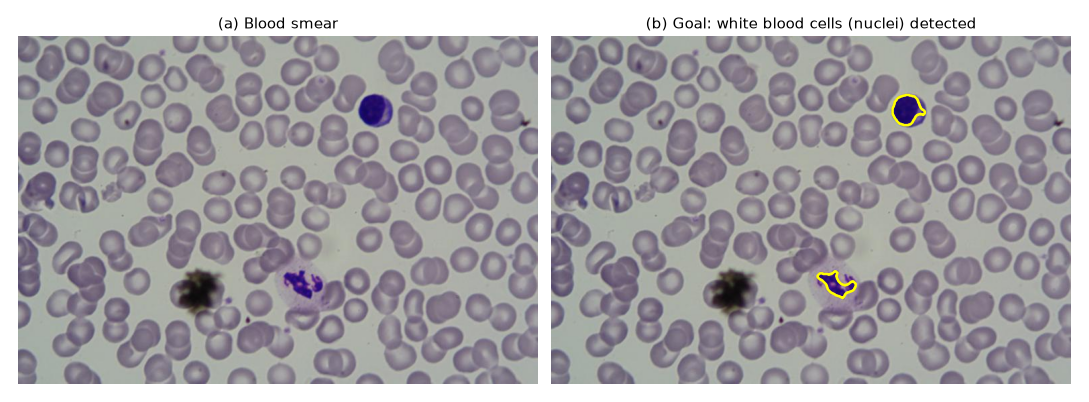

<span style="color:#009999;"> 
    
## 3. K-Means algorithm 
</span>

<span style="color:#009999;"> 
    
### 3.1 Clustering formulation
</span>

Clustering can be defined as the task of grouping a set of objects in such a way that objects in the same group (called cluster) are more similar (in some sense) to each other than to those in other groups [1]. K-Means looks for the partition of the data $D$ into $K$ clusters $C_1, \dots, C_K$ that minimizes the Sum of Squared Errors (SSE):

$$ \text{SSE} = \sum_{i=1}^{K} \sum_{x \in C_i} \| x - c_i \|^2 $$

where $c_i$ is the mean (= centroid) of cluster $C_i$ [2]. Minimizing the distances inside the clusters is equivalent to maximizing the dispersion between the clusters, since the total dispersion of the data is fixed.

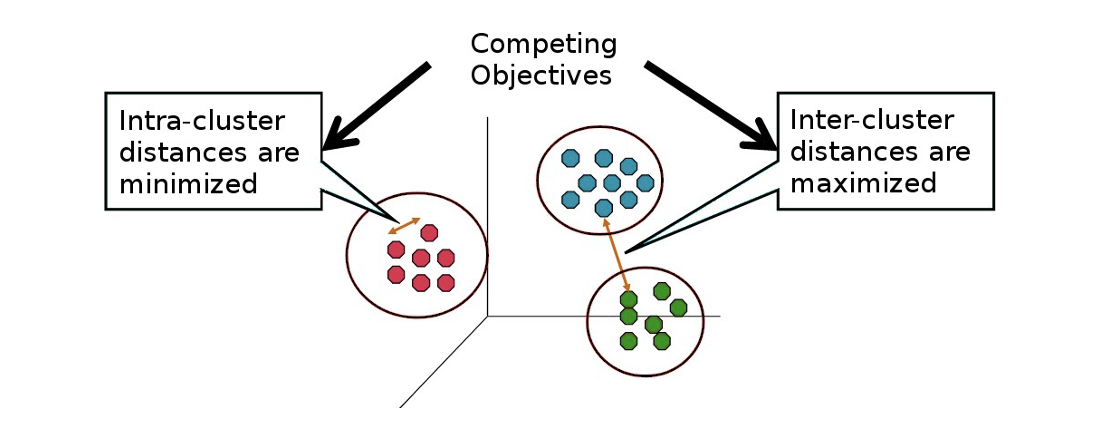

<span style="color:#009999;"> 

### 3.2 Pseudo-code
</span>

The algorithm alternates between two steps until no point changes cluster:

1. **Assignment step**: each data point is assigned to its nearest centroid (squared Euclidean distance).
2. **Update step**: each centroid is recomputed as the mean of the points assigned to its cluster.

<b>Algorithm 1: K-Means</b>

> **initialize** $K$ centroids $c_1, \dots, c_K$ (e.g. $K$ data points drawn at random) <br>
> **repeat** <br>
> &emsp; **foreach** $x \in D$: assign $x$ to its closest centroid, $\; i^* = \arg\min_i \| x - c_i \|^2$ <br>
> &emsp; **foreach** cluster $C_i$: recompute its centroid, $\; c_i = \frac{1}{|C_i|} \sum_{x \in C_i} x$ <br>
> **until** no point changes cluster

Each cluster $C_k$ is identified by a **label**, its index $k \in \{0, \dots, K-1\}$. The output of K-Means is therefore the **label of each point**, i.e. the index of the cluster (and thus of the closest centroid) it is assigned to, together with the $K$ centroids.

K-Means is guaranteed to converge, since the SSE can only decrease at each step. However, the result may be a **local** minimum, which depends on the initial centroids.

<span style="color:#009999;"> 
    
### 3.3 Feature space
</span>

K-Means does not know what it is clustering: it only sees a table $X$ of shape $(N, d)$, with one row per data point and one column per feature. The choice of the features is therefore crucial. For pixel clustering, the most common choice is the RGB space: each pixel is a point in a 3-dimensional space whose axes are its red, green and blue components [3].

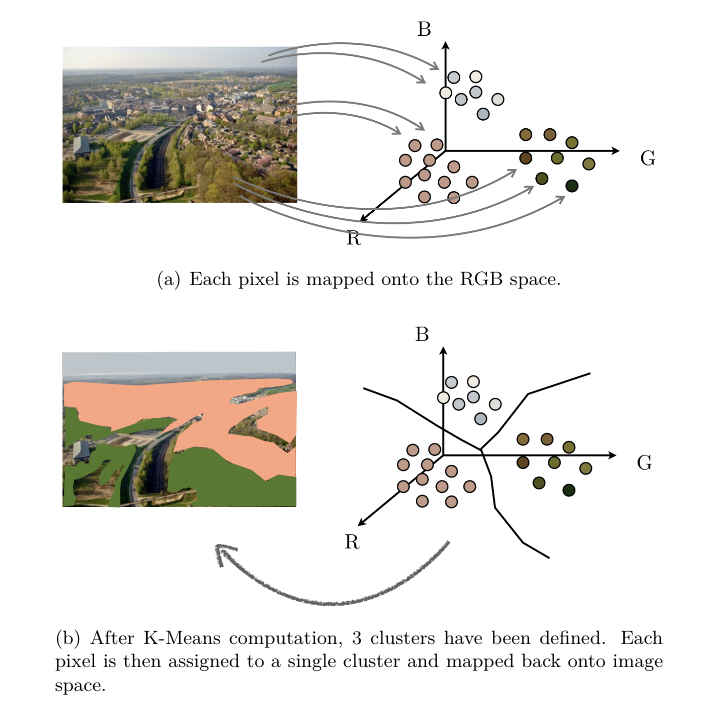

<span style="color:#009999;"> 

### Setup
</span>

Run this cell to load the image and a few helper functions.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.io import imread
from skimage.morphology import disk
from scipy.ndimage import binary_opening, binary_closing

original_img = imread('original_images/blood.jpg')[:, :, :3]
H, W, _ = original_img.shape
print('image shape:', original_img.shape)


def show_clusters(original_img, labels):
    """Return the image where each pixel takes the mean colour of its cluster."""
    rgb = original_img.reshape(-1, 3).astype(float)
    out = np.zeros_like(rgb)
    for k in np.unique(labels):
        out[labels == k] = rgb[labels == k].mean(axis=0)
    return out.round().astype(np.uint8).reshape(H, W, 3)


def show_images(images, titles):
    """Display several images side by side (RGB images of shape (H, W, 3) or binary masks of shape (H, W))."""
    fig, axes = plt.subplots(1, len(images), figsize=(6 * len(images), 4))
    for ax, image, title in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(image, cmap='gray' if image.ndim == 2 else None)
        ax.set_title(title)
        ax.axis('off')
    plt.show()


def show_contours(original_img, mask, title, ax=None):
    """Draw the contours of a binary mask of shape (H, W) on top of the image."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 4))
    ax.imshow(original_img)
    ax.contour(mask, levels=[0.5], colors='yellow', linewidths=2)
    ax.set_title(title)
    ax.axis('off')


def show_xy(original_img, X_xy, labels, centroids, title, ax=None):
    """Display the clusters of a set of pixel positions (x, y) of shape (N, 2) on top of the image."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 4))
    ax.imshow(original_img)
    ax.scatter(X_xy[:, 0], X_xy[:, 1], c=labels, s=1, cmap='brg')
    ax.scatter(centroids[:, 0], centroids[:, 1], marker='x', c='yellow', s=150, linewidths=3)
    ax.set_title(title)
    ax.axis('off')

<span style="color:#009999;"> 

### 4. Exercise 1 - K-Means in the RGB space
</span>

Implement the function `KMeans` following Algorithm 1, then apply it to the pixels of the image described by their RGB values (scaled to $[0, 1]$).

**Tip:** avoid looping over the pixels (there are about 400 000 of them, this would take several minutes): for each centroid, compute its distance to all the points at once, with numpy operations on whole arrays.

In [ ]:
def KMeans(X, K, init="random", seed=None):
    """
    K-Means clustering (Algorithm 1).
    INPUT :
        - X    : data, array of shape (N, d), one row per point
        - K    : number of clusters
        - init : "random" (K points drawn at random) or "kmeans++" (Exercise 3)
        - seed : random seed, to obtain the same result at each run (None = different at each run)
    OUTPUT :
        - labels    : array of shape (N,), cluster index of each point
        - centroids : array of shape (K, d)
    """

    return labels, centroids

In [ ]:
X_rgb =  original_img.reshape(-1, 3) / 255                     # one row per pixel, values in [0, 1]

labels_rgb, centroids_rgb = KMeans(X_rgb, 3, seed=0)

show_images([original_img, show_clusters(original_img, labels_rgb)], ['Original image', 'K-Means in RGB, K = 3'])

<div class="alert alert-info">

**QUESTION 1**

Run K-Means with $K = 2$ and $K = 4$ and compare with $K = 3$. Which value would you choose to detect the white blood cells? Justify.

<i>Your answer here.</i>

<span style="color:#009999;"> 

### 5. Exercise 2 - Separating the cells with the pixel positions
</span>

 We now want to **separate the individual cells** found in the darkest cluster.

1. Build a binary mask of the darkest cluster of Exercise 1.
2. This mask contains many small isolated dark spots (dust, cell borders). Remove them with a
**binary opening** using a disk of radius 5 pixels: an erosion, that deletes the
structures smaller than the disk, followed by a dilation, that restores the size of the remaining ones.
3. Build a new data table `X_xy` of shape $(N, 2)$, with one row per pixel of the cleaned mask and two features: its column $x$ and its row $y$ (the colour is not used anymore). Run `KMeans(X_xy, 3)` to group the pixels of the mask into 3 clusters according to their **position** only.

Since the result depends on the initial centroids, run K-Means with **20 different seeds**
(argument `seed` of `KMeans`) and compare the SSE of the runs.

In [ ]:
dark = ...
mask = ...

<div class="alert alert-info">

**QUESTION 2**

Why is the binary opening needed before clustering the positions? 
<br>How many of the 20 runs fail to separate the three blobs? Explain what happens in a failed run.

<i>Your answer here.</i>

<span style="color:#009999;"> 

### 6. Exercise 3 - K-Means++ initialization
</span>

K-Means++ [4] only changes the **initialization**: it draws initial centroids
that are far apart from each other.

1. The first centroid is a data point drawn at random.
2. For each point $x$, compute $dist(x)$, its distance to the **closest** centroid already chosen.
3. Draw the next centroid at random, with a probability proportional to $dist(x)^2$ (`np.random.choice(N, p=...)`).
4. Repeat steps 2 and 3 until $K$ centroids are chosen.

Implement `init_kmeanspp()`, then run again the 20 seeds of Exercise 2 with `init="kmeans++"`.

In [ ]:
def init_kmeanspp(X, K):
    """K-Means++ initialization: returns K initial centroids, array of shape (K, d)."""

    return centroids

<div class="alert alert-info">

**QUESTION 3**

How many runs fail with K-Means++? Why does this initialization help? Why is the next centroid drawn with a probability proportional to $dist(x)^2$, rather than simply chosen as the farthest point?

<i>Your answer here.</i>

<span style="color:#009999;"> 

### 7. Exercise 4 - Choosing the right features
</span>

Look again at the three blobs found in Exercises 2 and 3, and at the original image. Propose a new **colour feature** and **run K-Means again on the original image** (all its pixels, as in Exercise 1, not only the pixels of the mask), described by this feature instead of their RGB values, so as to keep only the white blood cells.

<div class="alert alert-info">

**QUESTION 4**

Are the three blobs all white blood cells? What distinguishes the nuclei from the black blob? 
<br>Which feature did you choose and why does it work better than RGB?

<i>Your answer here.</i>

## References
[1] LV Bijuraj. Clustering and its applications. In Proceedings of National Conference on New Horizons in IT-NCNHIT, page 169, 2013. <br>
[2] Clustering, Paolo Ferragina, Dipartimento di Informatica, Università di Pisa. http://slideplayer.com/slide/8363774/ <br>
[3] Slides from LELEC2885 Image Processing and Computer Vision, Laurent Jacques. <br>
[4] D. Arthur and S. Vassilvitskii. k-means++: the advantages of careful seeding. In Proceedings of the ACM-SIAM Symposium on Discrete Algorithms (SODA), 2007.